# All experiments — final comparison

**Run after [01_baseline.ipynb](01_baseline.ipynb) and one or more parameter notebooks.** Completed runs from this new workflow are discovered automatically and evaluated together using one real-trained detector and account split.

With zero runs, the notebook prints the next step and skips scoring. With only a baseline, it reports that reference without claiming a winner. Additional completed runs appear automatically. This notebook never trains a generator or generates synthetic data.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    completed_runs,
)


## 1. Find your completed runs

Only the shared `transaction_tuning_from_scratch` workflow directory is searched. No historical guidance runs or old model checkpoints are assumed. Dataset identity and artifact checksums are checked; partial runs are excluded.

In [2]:
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BOOTSTRAP_REPETITIONS = 200
EVALUATION_SEED = 42
THRESHOLD = 0.5
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
print(f"Completed runs found: {len(RUN_DIRS)}")
if not RUN_DIRS:
    print("No experiments have completed yet. Prepare the account cohort and run 01_baseline.ipynb; return here after generation.")

print(f"Selected processed dataset: {DATA_DIR}")


Completed runs found: 32
Selected processed dataset: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


In [3]:
import json

import yaml


rows = []
for directory in RUN_DIRS:
    config = yaml.safe_load((directory / "config.yaml").read_text())
    manifest = json.loads((directory / "manifest.json").read_text())
    row = {"dataset": directory.name, "model_source": "fresh",
           "sampling_seed": config["sampling_seed"], "training_seed": config["training_seed"],
           "run_directory": str(directory), "model_id": manifest.get("model_id"),
           "runner_fingerprint": manifest.get("context", {}).get("backend", {}).get("runner")}
    for section in ["sampling_config", "clustering_config", "diffusion_config", "classifier_config"]:
        for key, value in config[section].items():
            row[f"{section}.{key}"] = json.dumps(value) if isinstance(value, (list, dict)) else value
    rows.append(row)
RUN_SETTINGS = pd.DataFrame(rows).set_index("dataset") if rows else pd.DataFrame()
if rows:
    show(RUN_SETTINGS)


,model_source,sampling_seed,training_seed,run_directory,model_id,runner_fingerprint,sampling_config.batch_size,sampling_config.classifier_scale,sampling_config.sample_scale,clustering_config.num_clusters,...,diffusion_config.weight_decay,diffusion_config.scheduler,diffusion_config.data_split_ratios,diffusion_config.merge_categoricals_into_numerical,classifier_config.d_layers,classifier_config.lr,classifier_config.dim_t,classifier_config.batch_size,classifier_config.iterations,classifier_config.data_split_ratios
dataset,,,,,,,,,,,,,,,,,,,,,
0206fdd9c07b79be9bb0,fresh,42,46,/home/armoso/repo/vector-bootcamp-synthetic-da...,6a3b87ae586cefc32432,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00010,128,256,5000,"[0.7, 0.2, 0.1]"
070395331f946390ec55,fresh,42,43,/home/armoso/repo/vector-bootcamp-synthetic-da...,cf5c17f0d994269d5ce8,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00010,128,128,5000,"[0.7, 0.2, 0.1]"
0944c0b181da0e1f5a68,fresh,42,42,/home/armoso/repo/vector-bootcamp-synthetic-da...,ec278c7f6ef736772c01,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00010,256,256,5000,"[0.7, 0.2, 0.1]"
0b3221dc68e35cbcdf3b,fresh,42,43,/home/armoso/repo/vector-bootcamp-synthetic-da...,144e1181b71a714df4a2,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 256, 128]",0.00010,128,256,5000,"[0.7, 0.2, 0.1]"
11852d2ed893e569743c,fresh,42,43,/home/armoso/repo/vector-bootcamp-synthetic-da...,79517e3eea2b062fe703,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00010,128,256,2500,"[0.7, 0.2, 0.1]"
1ad42a2a58b436a4473b,fresh,42,44,/home/armoso/repo/vector-bootcamp-synthetic-da...,33449d6a555f8a53f218,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00010,128,256,10000,"[0.7, 0.2, 0.1]"
25a9a11abdaca5702ef9,fresh,42,42,/home/armoso/repo/vector-bootcamp-synthetic-da...,f9c2872bf34fd960dfbf,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00003,128,256,5000,"[0.7, 0.2, 0.1]"
306d581e62a492901dee,fresh,42,44,/home/armoso/repo/vector-bootcamp-synthetic-da...,3d8eb34530b1795a2d89,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00030,128,256,5000,"[0.7, 0.2, 0.1]"
3a0f2481e5e0cad98e5f,fresh,42,44,/home/armoso/repo/vector-bootcamp-synthetic-da...,256fea8a00da51bb100c,a8b4164c43fddb32bdf964693f04b674a1aa027abc5f7d...,8192,1.0,1.0,50,...,0.00001,cosine,"[0.7, 0.2, 0.1]",True,"[128, 256, 512, 1024, 512, 256, 128]",0.00010,128,256,5000,"[0.7, 0.2, 0.1]"


## 2. Evaluate saved synthetic data on CPU

The same real account split and detector are used for every selected run. A single baseline is enough to evaluate fidelity; at least one additional variant is needed to compare hyperparameters. Reports include event counts, source/settings fingerprints, fixed predictions, detailed CSVs, and plots.

In [4]:
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(
        DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=BOOTSTRAP_REPETITIONS,
        seed=EVALUATION_SEED, threshold=THRESHOLD,
    )
    print(f"Report saved to: {REPORT_DIR}")
    show(pd.read_json(REPORT_DIR / "real_split_counts.json"))
else:
    print("Evaluation skipped: create a baseline in 01_baseline.ipynb first.")

if comparison is not None:
    comparison_with_settings = comparison.join(RUN_SETTINGS)
    comparison_with_settings.to_csv(REPORT_DIR / "comparison_with_settings.csv")
    if len(RUN_DIRS) == 1:
        print("One completed run: this is a reference report, not a parameter comparison yet.")


Evaluating 0206fdd9c07b79be9bb0
Evaluating 070395331f946390ec55
Evaluating 0944c0b181da0e1f5a68
Evaluating 0b3221dc68e35cbcdf3b
Evaluating 11852d2ed893e569743c
Evaluating 1ad42a2a58b436a4473b
Evaluating 25a9a11abdaca5702ef9
Evaluating 306d581e62a492901dee
Evaluating 3a0f2481e5e0cad98e5f
Evaluating 3a2d482a68ec9e9c5b6e
Evaluating 3b2ecfa528f8bbb957f0
Evaluating 4e6cb8911daa317d3ffe
Evaluating 60817dddf379c0070725
Evaluating 740a241b085751dc8976
Evaluating 83e27ff821d61e94eabd
Evaluating 8531a4c1796cadfa3a1b
Evaluating 86ed1bf7aeb5ee075507
Evaluating 909bd3ef39f211da51a9
Evaluating 91c6e106f66fe99a9b4f
Evaluating 961b0650d8590a5a6775
Evaluating 9b26bf18c7b18b9a9732
Evaluating 9bb7a53c0190c3b85889
Evaluating adf20ad76b306cf8ad04
Evaluating b4ac3c7da2730cc56fca
Evaluating c6723f4200232a1b2d14
Evaluating ccfbac82e9bf0aab7cf2
Evaluating cd747b0a7ff6e7c73bc8
Evaluating db56cca1027418cfb4bd
Evaluating f56ae98fdfd44e788b1a
Evaluating fb3df20a556f617fe69c
Evaluating fc538633d32265a17459
Evaluati

,train,test
transactions,94313,23247
accounts,400,100
overdrafts,208,39


## 3. Overdraft transfer and uncertainty

AP describes how well overdrafts appear near the top of the scores; report prevalence alongside it. Standardized AP controls only the class-prior difference. ROC-AUC is complementary. Fixed-threshold precision/recall use 0.5 without tuning on these outcomes.

The 95% account-bootstrap intervals condition on the fitted detector and saved generation. Check event counts and valid bootstrap draws; missing/one-class scores are not good results. Repeated generation/training seeds address different uncertainty. This real→synthetic analysis does not establish synthetic-trained generalization to independent real accounts.

,rows,overdrafts,overdraft_prevalence,average_precision,average_precision_low,average_precision_high,standardized_ap,roc_auc,precision,recall,bootstrap_valid
dataset,,,,,,,,,,,
real_test,23247,39,0.0017,0.2422,0.0005,0.3606,0.2422,0.8722,0.0415,0.5385,199
0206fdd9c07b79be9bb0,88855,154,0.0017,0.0038,0.0032,0.0049,0.0037,0.7513,0.0017,0.0260,200
070395331f946390ec55,123320,211,0.0017,0.0059,0.0033,0.0166,0.0058,0.6966,0.0037,0.0569,200
0944c0b181da0e1f5a68,96722,297,0.0031,0.0090,0.0074,0.0107,0.0049,0.7919,0.0033,0.0269,200
0b3221dc68e35cbcdf3b,123885,179,0.0014,0.0032,0.0025,0.0043,0.0037,0.6921,0.0036,0.0670,200
11852d2ed893e569743c,120247,191,0.0016,0.0031,0.0026,0.0045,0.0033,0.6666,0.0037,0.0628,200
1ad42a2a58b436a4473b,143874,421,0.0029,0.0133,0.0115,0.0154,0.0076,0.8113,0.0078,0.0689,200
25a9a11abdaca5702ef9,95917,239,0.0025,0.0067,0.0058,0.0083,0.0045,0.7696,0.0029,0.0293,200
306d581e62a492901dee,142770,425,0.0030,0.0133,0.0111,0.0163,0.0075,0.8067,0.0062,0.0518,200


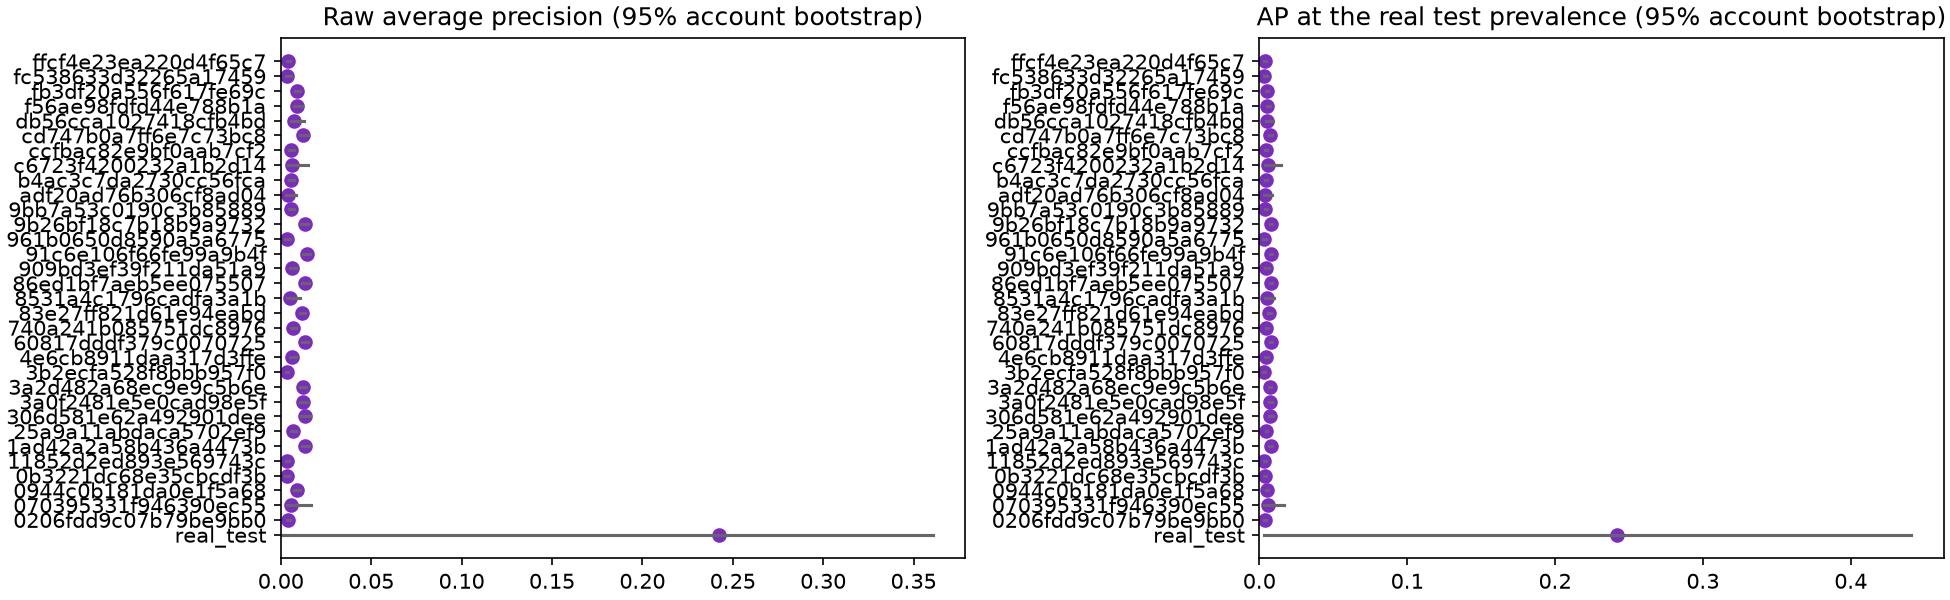

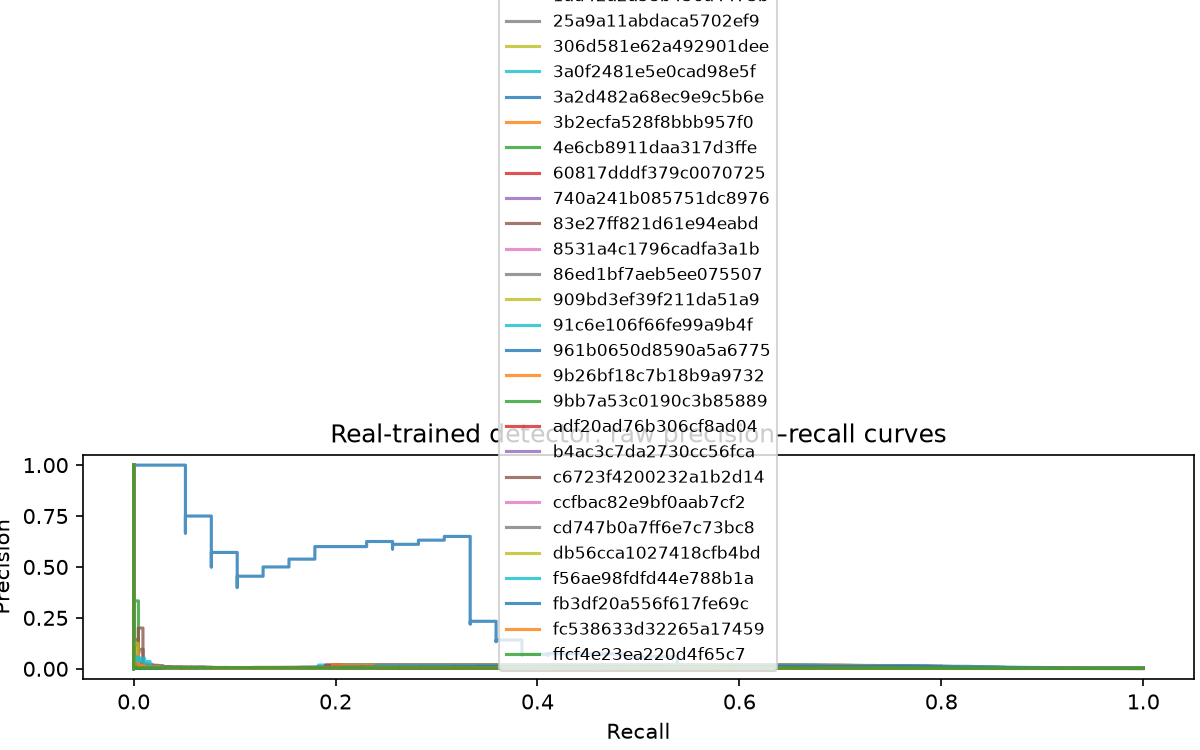

In [5]:
if comparison is not None:
    columns = ["rows", "overdrafts", "overdraft_prevalence", "average_precision",
               "average_precision_low", "average_precision_high", "standardized_ap",
               "roc_auc", "precision", "recall", "bootstrap_valid"]
    show(comparison[columns].round(4))
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "precision_recall.png")))


## 4. Transaction quality and account relationships

Lower distances indicate closer distributions; valid links and unique primary keys should have rates of 1. Numeric KS covers date, amount, and balance. Categorical TVD covers transaction categories. Identifiers, including external counterparty numbers, are excluded from those measurements.

Overdraft-conditional diagnostics expose rare-event problems hidden by overall marginals. Account checks include counts (including zero-transaction accounts), volumes, mixed parent/child relationships, integrity, and dates aligned to their different epochs. Incomplete histories limit rolling and sequential-balance checks. Full real input data is the fidelity reference.

**Full-table quality is evaluated in the same call:** all declared tables, all direct parent/child edges, PK/FK integrity, cardinality including zero-child parents, distributions, within/cross-table mixed correlations, and client/account combinations through `disp`. Detailed tables are saved as `all_table_scores.csv`, `all_edge_scores.csv`, and `multi_parent_scores.csv`. Undefined scores are reported explicitly.

,transaction_ks,transaction_tvd,overdraft_numerical_ks,overdraft_categorical_tvd,transactions_per_account_ks,account_transaction_correlation_rmse,accounts_overdrawn_rate_gap,transaction_fk_valid_rate,transaction_pk_unique_rate,synthetic_transaction_before_account_rate,max_invalid_rate,max_unknown_category_rate,undefined_account_pairs
dataset,,,,,,,,,,,,,
0206fdd9c07b79be9bb0,0.0914,0.0159,0.3755,0.2124,0.0572,0.0301,0.2377,1.0,1.0,0.0,0.0,0.0,0.0
070395331f946390ec55,0.0926,0.0120,0.2088,0.1647,0.0386,0.0301,0.2313,1.0,1.0,0.0,0.0,0.0,0.0
0944c0b181da0e1f5a68,0.0836,0.0130,0.5416,0.3027,0.0390,0.0244,0.3890,1.0,1.0,0.0,0.0,0.0,0.0
0b3221dc68e35cbcdf3b,0.0942,0.0139,0.1919,0.1727,0.0328,0.0277,0.2181,1.0,1.0,0.0,0.0,0.0,0.0
11852d2ed893e569743c,0.0879,0.0138,0.2283,0.1929,0.0498,0.0307,0.2257,1.0,1.0,0.0,0.0,0.0,0.0
1ad42a2a58b436a4473b,0.0930,0.0139,0.5353,0.3057,0.0411,0.0319,0.3993,1.0,1.0,0.0,0.0,0.0,0.0
25a9a11abdaca5702ef9,0.0824,0.0121,0.4959,0.2749,0.0420,0.0260,0.3340,1.0,1.0,0.0,0.0,0.0,0.0
306d581e62a492901dee,0.0864,0.0133,0.5191,0.2998,0.0316,0.0322,0.3959,1.0,1.0,0.0,0.0,0.0,0.0
3a0f2481e5e0cad98e5f,0.0882,0.0132,0.5331,0.3054,0.0468,0.0286,0.3622,1.0,1.0,0.0,0.0,0.0,0.0


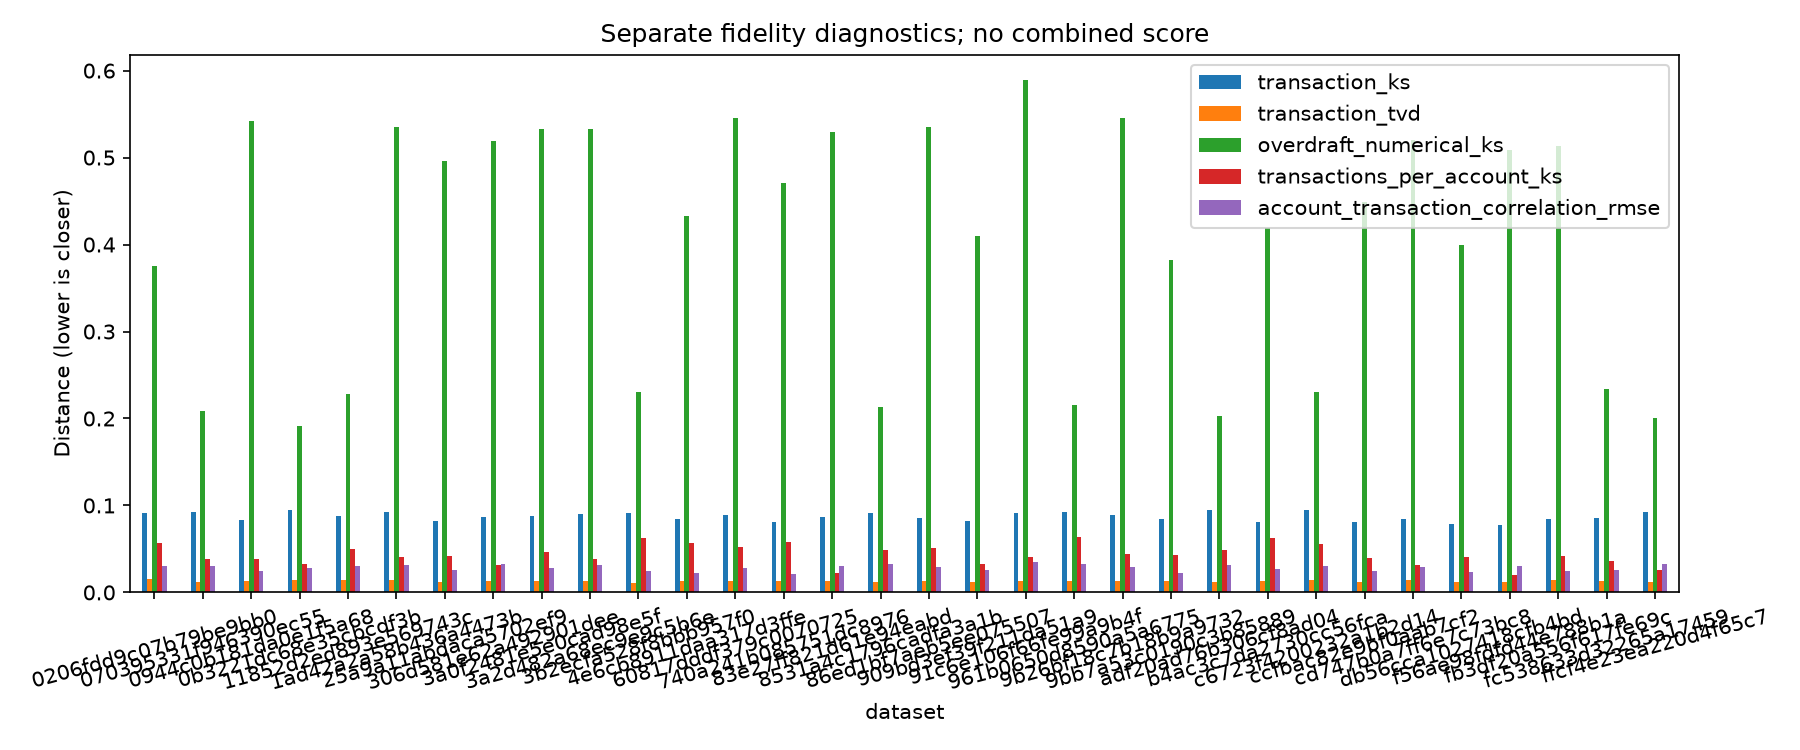

Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
0206fdd9c07b79be9bb0,8.0,8.0,0.0887,0.1041,0.0576,NaN,1.0,1.0,0.0378,0.1636,0.0,2.0
070395331f946390ec55,8.0,8.0,0.0948,0.0852,0.0442,NaN,1.0,1.0,0.0100,0.1338,0.0,2.0
0944c0b181da0e1f5a68,8.0,8.0,0.0815,0.0877,0.0466,NaN,1.0,1.0,0.0282,0.1465,0.0,2.0
0b3221dc68e35cbcdf3b,8.0,8.0,0.0938,0.0922,0.0464,NaN,1.0,1.0,0.0122,0.1159,0.0,2.0
11852d2ed893e569743c,8.0,8.0,0.1159,0.0803,0.0478,NaN,1.0,1.0,0.0193,0.1237,0.0,2.0
1ad42a2a58b436a4473b,8.0,8.0,0.0972,0.0847,0.0565,NaN,1.0,1.0,0.0247,0.1323,0.0,2.0
25a9a11abdaca5702ef9,8.0,8.0,0.0930,0.0999,0.0489,NaN,1.0,1.0,0.0297,0.1302,0.0,2.0
306d581e62a492901dee,8.0,8.0,0.0980,0.0934,0.0511,NaN,1.0,1.0,0.0114,0.1412,0.0,2.0
3a0f2481e5e0cad98e5f,8.0,8.0,0.0961,0.0970,0.0516,NaN,1.0,1.0,0.0194,0.1417,0.0,2.0


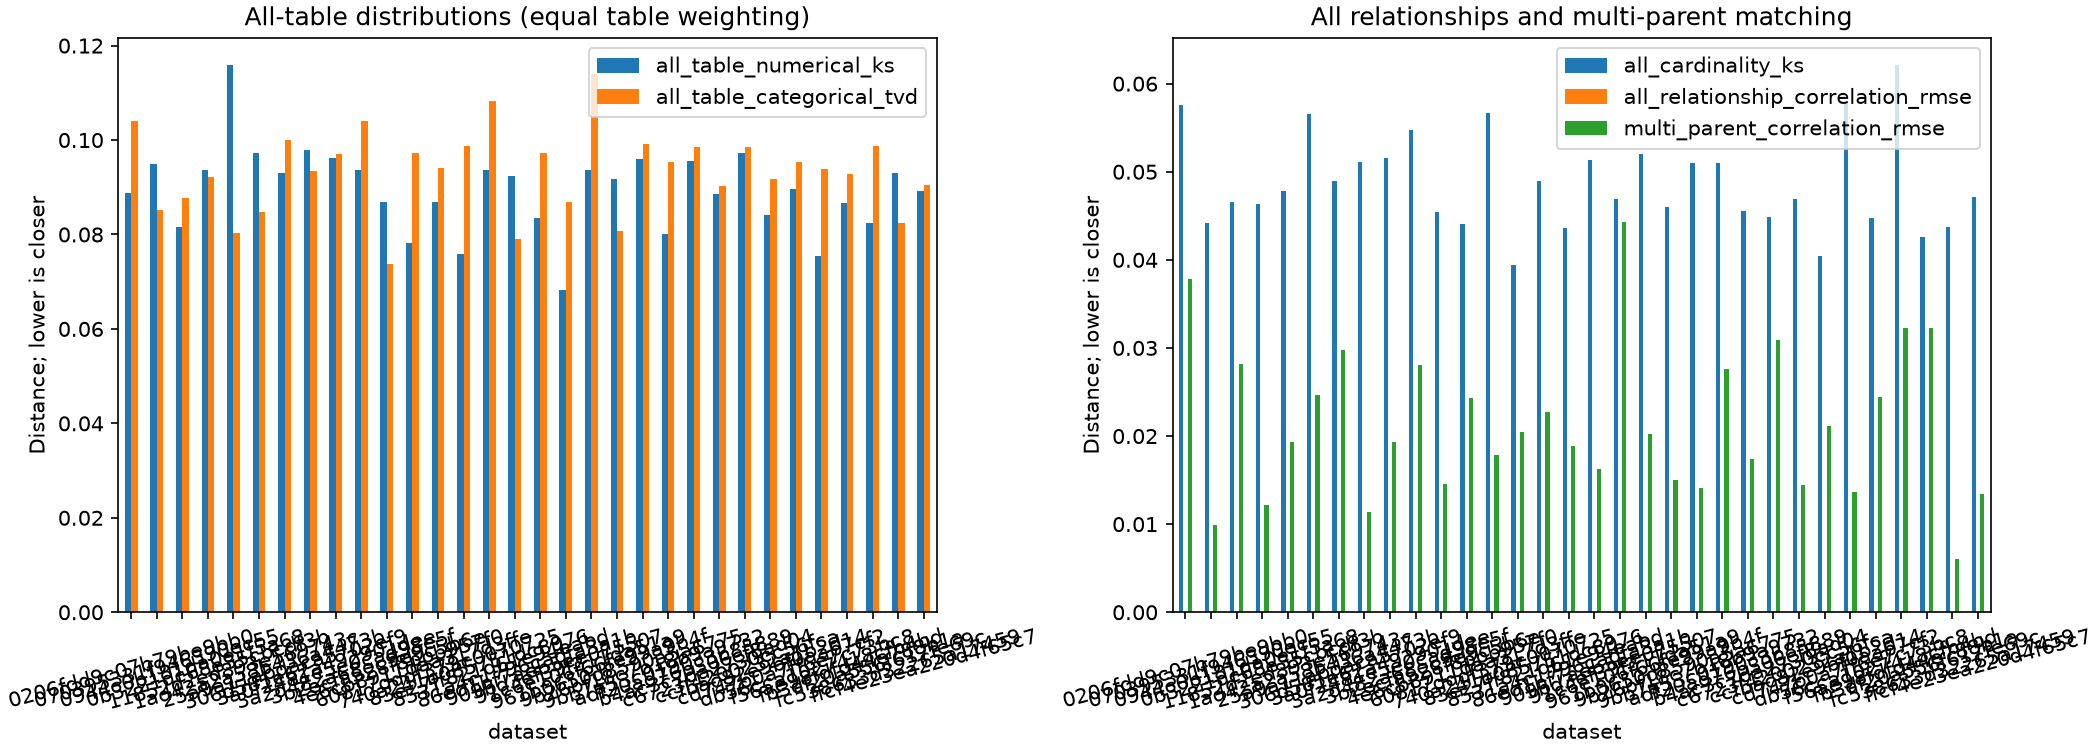

In [6]:
if comparison is not None:
    columns = ["transaction_ks", "transaction_tvd", "overdraft_numerical_ks",
               "overdraft_categorical_tvd", "transactions_per_account_ks",
               "account_transaction_correlation_rmse", "accounts_overdrawn_rate_gap",
               "transaction_fk_valid_rate", "transaction_pk_unique_rate",
               "synthetic_transaction_before_account_rate", "max_invalid_rate",
               "max_unknown_category_rate", "undefined_account_pairs"]
    show(comparison.loc[comparison.index != "real_test", columns].round(4))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Inspect a completed run

Category event rates include support and event counts; small groups are uncertain. Inspect overdraft-only distributions, missing/unknown values, and chronology before selecting a parameter. With no completed runs this cell does nothing.

In [7]:
if REPORT_DIR is not None:
    INSPECT_RUN = RUN_DIRS[0].name  # Change to another completed run name if desired.
    DETAIL_DIR = REPORT_DIR / INSPECT_RUN
    show(pd.read_csv(DETAIL_DIR / "distributions.csv").round(4))
    show(pd.read_csv(DETAIL_DIR / "conditional_distributions.csv").query("overdraft == 1").round(4))
    groups = pd.read_csv(DETAIL_DIR / "overdraft_by_category.csv")
    show(groups.sort_values("rate_error", ascending=False).head(12).round(4))

if REPORT_DIR is not None:
    show(pd.read_csv(DETAIL_DIR / "all_table_scores.csv").round(4))
    show(pd.read_csv(DETAIL_DIR / "all_edge_scores.csv").round(4))
    show(pd.read_csv(DETAIL_DIR / "multi_parent_scores.csv").round(4))


,column,metric,distance,real_n,synthetic_n,real_invalid_rate,synthetic_invalid_rate,synthetic_unknown_rate
0,trans_date,ks,0.1040,117560,88855,0.0,0.0,NaN
1,amount,ks,0.1362,117560,88855,0.0,0.0,NaN
2,balance,ks,0.0338,117560,88855,0.0,0.0,NaN
3,trans_type,tvd,0.0119,117560,88855,0.0,0.0,0.0
4,operation,tvd,0.0129,117560,88855,0.0,0.0,0.0
5,k_symbol,tvd,0.0181,117560,88855,0.0,0.0,0.0
6,bank,tvd,0.0206,117560,88855,0.0,0.0,0.0


,column,metric,distance,real_n,synthetic_n,real_invalid_rate,synthetic_invalid_rate,synthetic_unknown_rate,overdraft
7,trans_date,ks,0.2911,247,154,0.0,0.0,NaN,1
8,amount,ks,0.4010,247,154,0.0,0.0,NaN,1
9,balance,ks,0.4345,247,154,0.0,0.0,NaN,1
10,trans_type,tvd,0.0380,247,154,0.0,0.0,0.0,1
11,operation,tvd,0.4465,247,154,0.0,0.0,0.0,1
12,k_symbol,tvd,0.2767,247,154,0.0,0.0,0.0,1
13,bank,tvd,0.0882,247,154,0.0,0.0,0.0,1


,column,category,real_count,real_sum,real_mean,synthetic_count,synthetic_sum,synthetic_mean,rate_error,category_label
13,k_symbol,4,122.0,63.0,0.5164,18.0,0.0,0.0000,0.5164,SANKC. UROK
8,operation,5,788.0,0.0,0.0000,643.0,55.0,0.0855,0.0855,VYBER KARTOU
17,k_symbol,8,1594.0,0.0,0.0000,995.0,19.0,0.0191,0.0191,UVER
12,k_symbol,3,1732.0,1.0,0.0006,342.0,3.0,0.0088,0.0082,POJISTNE
21,bank,11,2432.0,20.0,0.0082,1996.0,1.0,0.0005,0.0077,UV
1,trans_type,1,1993.0,11.0,0.0055,445.0,1.0,0.0022,0.0033,VYBER
7,operation,4,48536.0,184.0,0.0038,36864.0,58.0,0.0016,0.0022,VYBER
5,operation,2,6824.0,19.0,0.0028,4596.0,4.0,0.0009,0.0019,PREVOD Z UCTU
31,bank,9,1803.0,1.0,0.0006,1164.0,2.0,0.0017,0.0012,QR
14,k_symbol,5,13106.0,11.0,0.0008,10162.0,18.0,0.0018,0.0009,SIPO


,table,real_rows,synthetic_rows,expected_rows_at_scale,relative_row_count_error,pk_unique_rate,pk_missing_or_invalid_rate,numerical_columns,categorical_columns,numerical_ks,categorical_tvd,max_invalid_rate,max_unknown_category_rate,within_table_correlation_rmse,correlation_pairs,undefined_pairs
0,district,77,77,77.0,0.0000,1.0,0.0,13,2,0.1079,0.3312,0.0,0.0,0.2688,105,0
1,client,596,438,596.0,0.2651,1.0,0.0,0,4,NaN,0.1274,0.0,0.0,0.0761,6,0
2,account,500,378,500.0,0.2440,1.0,0.0,1,1,0.0659,0.0338,0.0,0.0,0.0084,1,0
3,disp,596,438,596.0,0.2651,1.0,0.0,0,1,NaN,0.0627,0.0,0.0,NaN,0,0
4,card,90,52,90.0,0.4222,1.0,0.0,1,1,0.1077,0.0573,0.0,0.0,0.0011,1,0
5,loan,76,46,76.0,0.3947,1.0,0.0,4,1,0.1299,0.0858,0.0,0.0,0.1926,10,0
6,order,742,549,742.0,0.2601,1.0,0.0,1,2,0.0295,0.1190,0.0,0.0,0.0123,3,0
7,trans,117560,88855,117560.0,0.2442,1.0,0.0,3,4,0.0914,0.0159,0.0,0.0,0.0164,21,0


,edge,fk_valid_rate,invalid_foreign_keys,synthetic_child_rows,cardinality_ks,real_mean_children,synthetic_mean_children,real_fraction_zero_children,synthetic_fraction_zero_children,correlation_rmse,pairs,undefined_pairs,real_joined_rows,synthetic_joined_rows,join_status
0,district->client,1.0,0,438,0.1429,7.7403,5.6883,0.000,0.0000,0.0241,60,0,596,438,valid
1,district->account,1.0,0,378,0.1429,6.4935,4.9091,0.000,0.0000,0.0859,30,0,500,378,valid
2,client->disp,1.0,0,438,0.0000,1.0000,1.0000,0.000,0.0000,0.0286,4,0,596,438,valid
3,account->disp,1.0,0,438,0.0333,1.1920,1.1587,0.000,0.0000,0.0017,2,0,596,438,valid
4,disp->card,1.0,0,52,0.0323,0.1510,0.1187,0.849,0.8813,NaN,2,2,90,52,valid
5,account->loan,1.0,0,46,0.0303,0.1520,0.1217,0.848,0.8783,0.1456,10,0,76,46,valid
6,account->order,1.0,0,549,0.0217,1.4840,1.4524,0.184,0.1878,0.0160,6,0,742,549,valid
7,account->trans,1.0,0,88855,0.0572,235.1200,235.0661,0.000,0.0000,0.0301,14,0,117560,88855,valid


,relationship,correlation_rmse,pairs,undefined_pairs,real_joined_rows,synthetic_joined_rows,join_status,joint_categorical_tvd
0,client->disp<-account,0.0378,8,0,596,438,valid,0.1636


## Final conclusions — date representation (2026-11-12)

### Step 3: relative dates vs absolute (report `02dd0ec23c417328`)

Baseline × training seeds 42/43/44, sampling seed 42. Absolute reruns reproduce the step-1 matching-fix runs exactly (every metric identical), so the runner change did not alter results.

| Seed (absolute → relative) | 42 | 43 | 44 |
| --- | --- | --- | --- |
| Transactions before account opening (real 0%) | 20.5% → **0%** | 23.1% → **0%** | 16.1% → **0%** |
| Days-since-opening KS | 0.209 → **0.009** | 0.234 → **0.012** | 0.164 → **0.022** |
| Loan vs account-opening date correlation (real 0.958) | −0.115 → **0.970** | 0.038 → **0.953** | −0.134 → **0.956** |
| Transactions after data end (day 2188) | 0% → **24.5%** | 0% → **23.6%** | 0% → **19.4%** |
| Calendar `trans_date` KS | 0.005 → 0.245 | 0.014 → 0.236 | 0.044 → 0.194 |

Offsets were not bounded by the observation end, so the error moved from before opening to after the data end. Not adopted.

### Step 3b: window fraction vs absolute (report `8351cbcb96323721`)

`fraction_of_window` stores `(date − opening) / (data end − opening)`. Same seeds; absolute reruns again identical to step 1.

| Seed (absolute → window fraction) | 42 | 43 | 44 |
| --- | --- | --- | --- |
| Transactions before opening / after data end | 20.5% / 0% → **0% / 0%** | 23.1% / 0% → **0% / 0%** | 16.1% / 0% → **0% / 0%** |
| Fractions clipped on decode | — → 0 | — → 0 | — → 0 |
| Days-since-opening KS | 0.209 → 0.126 | 0.234 → 0.120 | 0.164 → 0.086 |
| Calendar `trans_date` KS | 0.005 → 0.129 | 0.014 → 0.129 | 0.044 → 0.109 |
| Loan vs account-opening date correlation (real 0.958) | −0.115 → 0.897 | 0.038 → 0.843 | −0.134 → 0.821 |
| Account→transaction correlation RMSE | 0.110 → **0.029** | 0.134 → **0.027** | 0.093 → **0.019** |
| Accounts ever overdrawn (real 5.6%) | 58.1% → 47.1% | 51.8% → 47.7% | 43.9% → 40.0% |
| Overall transaction KS | 0.056 → 0.093 | 0.053 → 0.090 | 0.061 → 0.098 |
| Detector ROC-AUC | 0.769 → 0.661 | 0.614 → 0.659 | 0.653 → 0.658 |
| Standardized AP (real 0.2422) | 0.0056 → 0.0033 | 0.0034 → 0.0030 | 0.0036 → 0.0037 |

1. **Both chronology bounds now hold in every seed pair, with no clipping needed.**
2. **Cross-table date structure improved in all 3 pairs:** account→transaction correlation RMSE fell about 4×, and the loan vs opening correlation is now 0.82–0.90.
3. **Trade-off:** the calendar `trans_date` marginal is worse (KS 0.11–0.13 vs 0.005–0.044). This raises the overall transaction KS to about 0.09.
4. **Overdrafts:** accounts ever overdrawn fell in all 3 pairs, but only by 4–11 points, and remain far from 5.6%. The transfer gap (~40×) is unchanged; ROC-AUC differences are within training noise.
5. **Decision:** adopt `fraction_of_window` as the date representation for the next steps (overdraft concentration, then re-tuning). These 3 runs are the new baseline.

### Step 4: `ever_overdrawn` account feature (CPU check of saved samples)

Baseline `fraction_of_window` reruns are identical to step 3b. The flag is a
training-only account column (real 5.6%), dropped before evaluation.

| Seed (baseline → feature) | 42 | 43 | 44 |
| --- | --- | --- | --- |
| Synthetic flag rate (real 0.056) | — → 0.073 | — → 0.053 | — → 0.060 |
| Accounts ever overdrawn (real 5.6%) | 47.1% → 46.4% | 47.6% → 48.2% | 40.0% → 31.0% |
| Negative rows within overdrawn accounts (real 3.6%) | 0.5% → 0.5% | 0.6% → 0.6% | 0.5% → 0.5% |

1. **The account model learns the flag**, but it reaches transactions only through cluster assignment, which does not concentrate overdrafts (one seed better, two flat).
2. **Decision:** reject; keep `account_feature: none`. Next: re-test `kmeans` clustering against the `fraction_of_window` baseline.

### Step 5: clustering method (report `a7b223c72a6c677d`)

Baseline `kmeans_and_gmm` vs `kmeans` and `gmm`, training seeds 42/43/44 (sampling seed 42). Real-test ROC-AUC 0.872, AP 0.2422.

| Seed 42 / 43 / 44 | baseline | `kmeans` | `gmm` |
| --- | --- | --- | --- |
| Detector ROC-AUC | 0.661 / 0.659 / 0.658 | 0.672 / **0.601** / **0.553** | 0.678 / 0.641 / 0.639 |
| Standardized AP | 0.0033 / 0.0030 / 0.0037 | 0.0033 / 0.0026 / 0.0100 | 0.0035 / 0.0028 / 0.0033 |
| Transaction KS | 0.093 / 0.090 / 0.098 | **0.062 / 0.074 / 0.078** | 0.080 / 0.096 / 0.092 |
| Calendar `trans_date` KS | 0.129 / 0.129 / 0.109 | **0.045 / 0.081 / 0.081** | 0.088 / 0.140 / 0.110 |
| Account→transaction correlation RMSE | 0.029 / 0.027 / 0.019 | 0.039 / 0.025 / 0.021 | 0.035 / 0.024 / 0.021 |
| Loan vs opening correlation (real 0.958) | 0.90 / 0.84 / 0.82 | 0.77 / 0.68 / 0.78 | 0.86 / 0.84 / 0.80 |
| Accounts ever overdrawn (real 5.6%) | 47.1 / 47.6 / 40.0% | 50.6 / 48.2 / 28.2% | 50.5 / 47.5 / 38.2% |

1. **`kmeans` improves transaction marginals in all 3 pairs** (transaction KS and calendar date KS), but the detector ROC-AUC falls in 2 of 3 pairs (by up to 0.10), and the loan correlation weakens in all 3.
2. **`gmm` is within noise of the baseline** on every metric.
3. **Decision:** keep `kmeans_and_gmm`. Detector transfer is the goal, and `kmeans` hurts it in 2 of 3 seeds. The `fraction_of_window` baseline stays the reference for diffusion and classifier tuning.

### Step 6: diffusion training iterations (report `edb433b7162d5fa9`)

Baseline 5000 vs 2500 and 10000, training seeds 42/43/44 (sampling seed 42).

| Seed 42 / 43 / 44 | 2500 | 5000 (baseline) | 10000 |
| --- | --- | --- | --- |
| Detector ROC-AUC | 0.533 / 0.726 / 0.783 | 0.661 / 0.659 / 0.658 | **0.762 / 0.680 / 0.700** |
| Standardized AP | 0.0016 / 0.0052 / 0.0069 | 0.0033 / 0.0030 / 0.0037 | **0.0040 / 0.0033 / 0.0039** |
| Transaction TVD | 0.034 / 0.031 / 0.031 | 0.023 / 0.023 / 0.031 | **0.018 / 0.014 / 0.018** |
| All-table numerical KS | 0.162 / 0.177 / 0.161 | 0.097 / 0.109 / 0.131 | **0.076 / 0.096 / 0.093** |
| Account→transaction correlation RMSE | 0.028 / 0.027 / 0.022 | 0.029 / 0.027 / 0.019 | 0.022 / 0.030 / 0.028 |
| Accounts ever overdrawn (real 5.6%) | 96 / 62 / 90% | 47 / 48 / 40% | **41 / 31 / 33%** |
| Loan vs opening correlation (real 0.958) | 0.80 / 0.78 / 0.73 | 0.90 / 0.84 / 0.82 | 0.89 / 0.85 / 0.89 |

1. **10000 beats 5000 in all 3 pairs** on detector ROC-AUC, standardized AP, transaction TVD, all-table numerical KS and overdrawn accounts. Only account→transaction correlation RMSE is slightly worse (2 of 3).
2. **2500 is unstable:** ROC-AUC ranges 0.53–0.78 and most accounts are overdrawn.
3. **Decision:** adopt 10000 diffusion iterations for fresh training. The overdraft gap is still large (31–41% vs 5.6%), so the next test is 20000 iterations against the new 10000 baseline.

### Step 7: diffusion training iterations 20000 (report `60063072d89dd766`)

Baseline 10000 vs 20000, training seeds 42/43/44 (sampling seed 42).

| Seed 42 / 43 / 44 | 10000 (baseline) | 20000 |
| --- | --- | --- |
| Detector ROC-AUC | 0.762 / 0.680 / 0.700 | 0.691 / 0.700 / 0.680 |
| Standardized AP | 0.0040 / 0.0033 / 0.0039 | 0.0040 / 0.0045 / 0.0040 |
| Transaction TVD | 0.018 / 0.014 / 0.018 | **0.013 / 0.014 / 0.011** |
| Transaction KS | 0.091 / 0.092 / 0.089 | **0.087 / 0.091 / 0.085** |
| All-table categorical TVD | 0.096 / 0.084 / 0.100 | **0.091 / 0.078 / 0.076** |
| All-table numerical KS | 0.076 / 0.096 / 0.093 | 0.085 / 0.079 / 0.078 |
| Account→transaction correlation RMSE | 0.022 / 0.030 / 0.028 | 0.020 / 0.029 / 0.031 |
| Accounts ever overdrawn (real 5.6%) | 41 / 31 / 33% | **25 / 28 / 24%** |

1. **20000 improves fidelity:** transaction TVD and KS, categorical TVD and overdrawn accounts are better in all 3 pairs, and numerical KS is better in 2 of 3.
2. **Detector transfer does not improve:** ROC-AUC is lower in 2 of 3 pairs (mean 0.714 → 0.690), and standardized AP is within noise.
3. **Decision:** keep 10000. As in step 5, detector transfer is the goal, and 20000 also doubles diffusion training time. 20000 remains the best fidelity setting if fidelity becomes the target.

### Step 8: diffusion presets (report `43e7f4d2b0d8d13d`)

Baseline (10000 iterations, lr 0.0006, batch 256, dropout 0, 500 timesteps) vs one change each, training seeds 42/43/44. The baseline values match step 7 exactly. "(n/3)" is the number of seed pairs better than the baseline.

| Seed 42 / 43 / 44 | Detector ROC-AUC | Standardized AP | Transaction TVD | Accounts ever overdrawn (real 5.6%) |
| --- | --- | --- | --- | --- |
| baseline | 0.762 / 0.680 / 0.700 | 0.0040 / 0.0033 / 0.0039 | 0.018 / 0.014 / 0.018 | 41 / 31 / 33% |
| **batch 512** | **0.770 / 0.691 / 0.806 (3/3)** | **0.0051 / 0.0036 / 0.0074 (3/3)** | **0.012 / 0.012 / 0.013 (3/3)** | 38 / 29 / 42% (2/3) |
| batch 128 | 0.797 / 0.661 / 0.686 (1/3) | 0.0077 / 0.0030 / 0.0040 (2/3) | 0.026 / 0.020 / 0.023 (0/3) | 65 / 39 / 39% (0/3) |
| smaller model | 0.731 / 0.735 / 0.709 (2/3) | 0.0037 / 0.0035 / 0.0034 (1/3) | 0.021 / 0.021 / 0.020 (0/3) | 62 / 66 / 57% (0/3) |
| dropout 0.1 | 0.647 / 0.648 / 0.586 (0/3) | 0.0029 / 0.0029 / 0.0032 (0/3) | 0.023 / 0.024 / 0.020 (0/3) | 62 / 54 / 41% (0/3) |
| dropout 0.2 | 0.724 / 0.708 / 0.695 (1/3) | 0.0038 / 0.0032 / 0.0028 (0/3) | 0.038 / 0.036 / 0.033 (0/3) | 91 / 76 / 93% (0/3) |
| lr 0.0002 | 0.666 / 0.547 / 0.585 (0/3) | 0.0032 / 0.0026 / 0.0022 (0/3) | 0.021 / 0.020 / 0.022 (0/3) | 55 / 32 / 70% (0/3) |
| lr 0.001 | 0.777 / 0.671 / 0.712 (2/3) | 0.0042 / 0.0034 / 0.0040 (3/3) | 0.018 / 0.015 / 0.017 (2/3) | 68 / 34 / 34% (0/3) |
| timesteps 250 | 0.708 / 0.720 / 0.693 (1/3) | 0.0041 / 0.0039 / 0.0042 (3/3) | 0.019 / 0.018 / 0.016 (1/3) | 32 / 34 / 36% (1/3) |
| timesteps 1000 | 0.669 / 0.688 / 0.740 (2/3) | 0.0038 / 0.0078 / 0.0045 (2/3) | 0.017 / 0.015 / 0.018 (1/3) | 35 / 36 / 43% (1/3) |

1. **Batch 512 is the only setting that improves both transfer metrics in all 3 pairs:** mean ROC-AUC 0.714 → 0.755 and standardized AP 0.0037 → 0.0054. It also improves transaction TVD in 3/3, and numerical KS, categorical TVD and cardinality KS in 2/3.
2. **Dropout, lr 0.0002 and the smaller model clearly hurt.** They spread overdrafts over many more accounts (up to 93%).
3. **lr 0.001 and both timestep settings are within noise.**
4. **Decision:** adopt diffusion batch size 512. Next: classifier presets against this baseline.

### Step 10: final configuration on 5 training seeds (report `c480bd90c664b936`)

Matching fix, `fraction_of_window` dates, `kmeans_and_gmm`, diffusion 10000 iterations / batch 512, classifier defaults. Seeds 42–44 reused from cache; 45 and 46 are new.

| Seed | 42 | 43 | 44 | 45 | 46 | Mean ± sd |
| --- | --- | --- | --- | --- | --- | --- |
| Detector ROC-AUC (real 0.872) | 0.770 | 0.691 | 0.806 | 0.768 | 0.751 | **0.757 ± 0.042** |
| Standardized AP (real 0.242) | 0.0051 | 0.0036 | 0.0074 | 0.0055 | 0.0037 | **0.0051 ± 0.0016** |
| Transaction TVD | 0.012 | 0.012 | 0.013 | 0.012 | 0.016 | 0.013 ± 0.002 |
| All-table numerical KS | 0.076 | 0.089 | 0.096 | 0.087 | 0.089 | 0.087 ± 0.008 |
| Accounts ever overdrawn (real 5.6%) | 38.3% | 29.3% | 41.8% | 38.9% | 29.4% | 35.5 ± 5.8% |

1. **The new seeds fall inside the 3-seed range**, so the step 8–9 conclusions hold.
2. **Structure is correct in every seed:** 0% transactions before opening, FK validity 1.0.
3. **Seed-to-seed ROC-AUC spread halved** versus the first baseline (sd 0.081 → 0.042).
4. **Remaining gap:** standardized AP is ~47× below real, and overdrafts are spread over ~35% of accounts vs 5.6%. Hyperparameter tuning is exhausted; next work is structural.

### Overdraft diagnosis and design D (CPU post-processing, report `overdraft_episodes/reports/32066784546dbc9d`)

Rule-based post-processing of the 5 step-10 runs (`experiments/analysis/overdraft_episodes.py`); no retraining. Calibration uses real train accounts only.

| Mean of seeds 42–46 | Original | Episodes only | Episodes + real row profile |
| --- | --- | --- | --- |
| Detector ROC-AUC (real 0.872) | 0.757 | 0.528 | 0.789 |
| Standardized AP (real 0.242) | 0.0051 | 0.0019 | 0.186 |
| Accounts ever overdrawn (real 5.6%) | 35.5% | 5.7% | 5.7% |
| Overdraft categorical TVD | 0.238 | 0.231 | 0.080 |

1. **Diagnosis:** synthetic negative balances have the right row share but are scattered (1 per account vs 4 in real) and lack the real overdraft row profile (0% penalty-interest rows vs 25.5%).
2. **Episodes only** fixes concentration but makes transfer random.
3. **Episodes + profile** brings AP close to real, but this is **circular**: the detector is trained on real data and recognises the injected profile. Diagnostic only, not a generator improvement.
4. Transaction and all-table KS/TVD are unchanged by both variants.

### Reverse test: train on synthetic, test on real (`overdraft_episodes/tstr/tstr.csv`)

Same random forest and features as the evaluator, trained on each synthetic `trans`, tested on the held-out real accounts (split seed 42).

| Mean of seeds 42–46 | ROC-AUC | AP |
| --- | --- | --- |
| Trained on real (reference) | 0.872 | 0.242 |
| Final synthetic | **0.887 ± 0.018** | **0.085 ± 0.022** |
| + episodes only | 0.674 | 0.003 |
| + episodes + real row profile (rules) | 0.812 | 0.223 |
| Random | 0.5 | 0.002 |

1. **Synthetic-trained detectors rank real overdrafts as well as real-trained ones** and reach 35% of real AP (~50× random). Real→synthetic AP (0.005) understates usefulness.
2. Episodes alone hurt in 5/5 seeds. Episodes + profile raise AP in 5/5 seeds but lower ROC-AUC in 5/5; the rules use real train accounts only (no leakage), but this is generator + rules.
3. Caveat: one real split, one detector seed.